#### CA3 – KNN

Målet er å forutsi vinkvalitet ut fra kjemiske målinger.


#### Imports

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

#### Settings

In [16]:
# Bruker samme datasplitt for alle innstillinger.
KNN_test_runs = 10
validation_size = 0.25
random_states = range(KNN_test_runs)

# n_neighbors er antall nærmeste viner.
# distance gir nærmere viner større vekt.
KNN_parameters = [
    {"n_neighbors": 3, "weights": "uniform"},
    {"n_neighbors": 5, "weights": "uniform"},
    {"n_neighbors": 7, "weights": "uniform"},
    {"n_neighbors": 9, "weights": "uniform"},
    {"n_neighbors": 11, "weights": "uniform"},
    {"n_neighbors": 15, "weights": "uniform"},
    {"n_neighbors": 5, "weights": "distance"},
    {"n_neighbors": 9, "weights": "distance"},
    {"n_neighbors": 15, "weights": "distance"},
]

#### Reading data

In [17]:
# CSV-filene må ligge i samme mappe.
df_wine = pd.read_csv("train.csv")
df_wine_test = pd.read_csv("test.csv")
sample_submission = pd.read_csv("sample_submission.csv")
print("Training:", df_wine.shape)
print("Test:", df_wine_test.shape)
display(df_wine.head())

Training: (835, 13)
Test: (209, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.8,0.610,0.29,1.6,0.114,9.0,29.0,0.99740,3.26,1.56,9.1,0,13
1,8.4,1.035,0.15,6.0,0.073,11.0,54.0,0.99900,3.37,0.49,9.9,0,705
2,8.1,0.290,0.36,2.2,0.048,35.0,53.0,0.99500,3.27,1.01,12.4,1,1408
3,5.2,0.340,0.00,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.0,1,144
4,15.6,0.645,0.49,4.2,0.095,10.0,23.0,1.00315,2.92,0.74,11.1,0,557


#### Data exploration

In [18]:
# Sjekker manglende verdier og fordeling.
features = [name for name in df_wine.columns if name not in ["Id", "ID", "quality"]]
print("Missing values:", df_wine.isna().sum().sum())
print("Repeated feature rows:", df_wine.duplicated(subset=features).sum())
print("Quality counts:\n", df_wine["quality"].value_counts().sort_index())
display(df_wine[features].describe().round(2))

Missing values: 0
Repeated feature rows: 75
Quality counts:
 quality
0    417
1    418
Name: count, dtype: int64


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
count,835.00,835.00,835.00,835.00,835.00,835.00,835.00,835.00,835.00,835.00,835.00
mean,8.31,0.54,0.26,2.54,0.09,15.86,47.08,1.00,3.31,0.66,10.40
std,1.76,0.18,0.20,1.42,0.05,10.44,33.27,0.00,0.16,0.18,1.09
min,4.60,0.12,0.00,0.90,0.01,1.00,7.00,0.99,2.74,0.33,8.40
25%,7.10,0.41,0.08,1.90,0.07,7.00,22.00,1.00,3.20,0.55,9.50
50%,7.90,0.54,0.24,2.20,0.08,13.00,38.00,1.00,3.31,0.61,10.10
75%,9.10,0.65,0.41,2.60,0.09,21.00,63.00,1.00,3.40,0.72,11.00
max,15.90,1.58,1.00,15.50,0.61,68.00,289.00,1.00,4.01,2.00,14.90


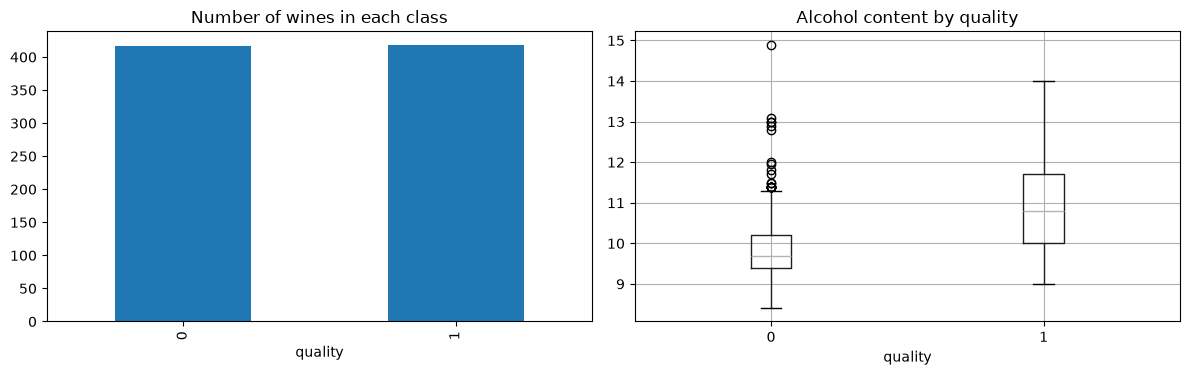

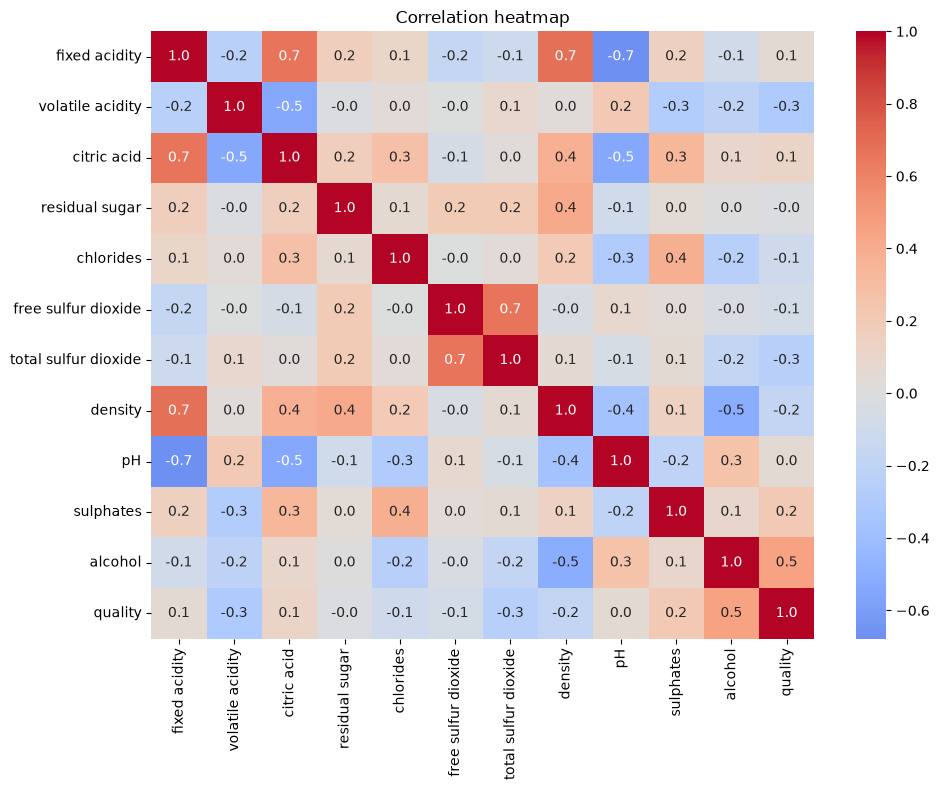

Correlation with quality:


volatile acidity       -0.302
total sulfur dioxide   -0.250
density                -0.179
chlorides              -0.103
free sulfur dioxide    -0.074
residual sugar         -0.020
pH                      0.050
fixed acidity           0.051
citric acid             0.111
sulphates               0.219
alcohol                 0.452
Name: quality, dtype: float64

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_wine["quality"].value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set_title("Number of wines in each class")
df_wine.boxplot(column="alcohol", by="quality", ax=axes[1])
axes[1].set_title("Alcohol content by quality")
plt.suptitle("")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(df_wine[features + ["quality"]].corr(), cmap="coolwarm", center=0, annot=True, fmt=".1f")
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

print("Correlation with quality:")
display(df_wine[features + ["quality"]].corr()["quality"].drop("quality").sort_values().round(3))

#### Data cleaning

In [20]:

assert df_wine[features + ["quality"]].isna().sum().sum() == 0
assert df_wine_test[features].isna().sum().sum() == 0
assert all(feature in df_wine_test.columns for feature in features)
print("No missing measurements; keeping all training observations.")

No missing measurements; keeping all training observations.


#### Data preprocessing

In [21]:

X = df_wine[features]
y = df_wine["quality"]
X_test = df_wine_test[features]
print("Training features:", X.shape, "Target:", y.shape)

Training features: (835, 11) Target: (835,)


#### KNN trials

In [22]:
# Tester innstillingene på samme datasplitt.

results = []
for parameters in KNN_parameters:
    split_scores = []
    for state in random_states:
        X_train, X_val, y_train, y_val = train_test_split(
            X, y, test_size=validation_size, random_state=state, stratify=y
        )
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_val_scaled = scaler.transform(X_val)

        clf = KNeighborsClassifier(**parameters)
        clf.fit(X_train_scaled, y_train)
        predictions = clf.predict(X_val_scaled)
        split_scores.append(accuracy_score(y_val, predictions))

    results.append({**parameters, "mean_accuracy": np.mean(split_scores),
                    "std_accuracy": np.std(split_scores)})

results_table = pd.DataFrame(results).sort_values("mean_accuracy", ascending=False)
display(results_table.round(4))

# Velger høyeste snitt fra ti tester.
best_row = results_table.iloc[0]
best_parameters = {
    "n_neighbors": int(best_row["n_neighbors"]),
    "weights": best_row["weights"]
}
print("Best settings:", best_parameters)
print(f"Mean validation accuracy: {best_row['mean_accuracy']:.2%}")

,n_neighbors,weights,mean_accuracy,std_accuracy
8,15,distance,0.7555,0.0276
7,9,distance,0.7531,0.0303
6,5,distance,0.7459,0.0240
3,9,uniform,0.7244,0.0329
4,11,uniform,0.7244,0.0317
1,5,uniform,0.7187,0.0246
5,15,uniform,0.7163,0.0272
2,7,uniform,0.7148,0.0330
0,3,uniform,0.6919,0.0273


Best settings: {'n_neighbors': 15, 'weights': 'distance'}
Mean validation accuracy: 75.55%


#### Model evaluation

Example split accuracy: 77.51%


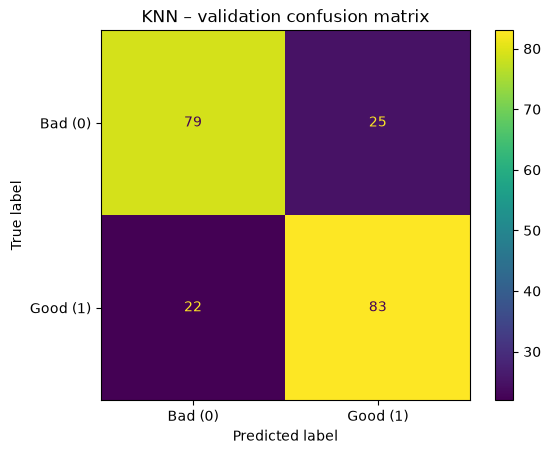

In [23]:
# Viser resultatet på ett datasplitt.
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=validation_size, random_state=42, stratify=y
)
check_scaler = StandardScaler()
X_train_scaled = check_scaler.fit_transform(X_train)
X_val_scaled = check_scaler.transform(X_val)
check_model = KNeighborsClassifier(**best_parameters)
check_model.fit(X_train_scaled, y_train)
y_val_pred = check_model.predict(X_val_scaled)
print(f"Example split accuracy: {accuracy_score(y_val, y_val_pred):.2%}")
ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred, display_labels=["Bad (0)", "Good (1)"])
plt.title("KNN – validation confusion matrix")
plt.show()

#### Kaggle export

In [24]:
# Trener KNN og lager prediksjoner til Kaggle.
final_scaler = StandardScaler()
X_scaled = final_scaler.fit_transform(X)
X_test_scaled = final_scaler.transform(X_test)
final_model = KNeighborsClassifier(**best_parameters)
final_model.fit(X_scaled, y)

submission = sample_submission.copy()
submission["quality"] = final_model.predict(X_test_scaled).astype(int)
assert len(submission) == len(df_wine_test)
assert submission.columns.tolist() == sample_submission.columns.tolist()
submission.to_csv("CA3_KNN_submission.csv", index=False)
print("Saved CA3_KNN_submission.csv")
display(submission.head())

Saved CA3_KNN_submission.csv


,ID,quality
0,0,1
1,1,1
2,2,0
3,3,1
4,4,0
